In [ ]:
%% Configuration du projet

project_root = pwd;
src_dir = fullfile(project_root, 'src');
figures_dir = fullfile(project_root, 'figures');

addpath(src_dir);

if ~exist(figures_dir, 'dir')
    mkdir(figures_dir);
end

# TP3 : Analyse Spectrale d'une Structure Élastique
## Modes de vibration d'un pont en 2D par méthodes de Krylov
### Réalisé par : Flavio DANTAS DE SENA - 4A MAM

## Partie 1 : Paramètres et assemblage de la matrice A

Dans cette première partie, on construit la matrice d’élasticité associée au problème de Navier en deux dimensions. Le domaine est discrétisé par une grille régulière de taille $n_x \times n_y$, avec un pas d’espace $h$.

En chaque point de la grille, on considère deux inconnues correspondant aux deux composantes du déplacement :

$$
u_{i,j} \quad \text{et} \quad v_{i,j}.
$$

Le vecteur inconnu global est donc de taille :

$$
N = 2 n_x n_y.
$$

L’indexation utilisée dans le code est la suivante :

$$
\text{idx}_u(i,j) = 2((j-1)n_x + (i-1)) + 1,
$$

$$
\text{idx}_v(i,j) = 2((j-1)n_x + (i-1)) + 2.
$$

Cela permet de stocker successivement les deux composantes de déplacement en chaque point de grille.

Le système discrétisé provient des équations de Navier en 2D :

$$
-(\lambda+2\mu)\frac{\partial^2 u}{\partial x^2}
-\mu\frac{\partial^2 u}{\partial y^2}
-(\lambda+\mu)\frac{\partial^2 v}{\partial x \partial y}
= \omega^2 \rho u,
$$

$$
-(\lambda+\mu)\frac{\partial^2 u}{\partial y \partial x}
-\mu\frac{\partial^2 v}{\partial x^2}
-(\lambda+2\mu)\frac{\partial^2 v}{\partial y^2}
= \omega^2 \rho v.
$$

On pose alors :

$$
c_1 = \lambda + 2\mu,
\qquad
c_2 = \mu,
\qquad
c_3 = \frac{\lambda+\mu}{4h^2}.
$$

Les dérivées secondes selon $x$ et $y$ sont approchées par le stencil classique à trois points, tandis que la dérivée croisée est approchée par :

$$
\frac{\partial^2 v}{\partial x\,\partial y}
\simeq
\frac{
v_{i+1,j+1}
- v_{i-1,j+1}
- v_{i+1,j-1}
+ v_{i-1,j-1}
}{4h^2}.
$$


Comme ce terme apparaît avec un signe négatif dans les équations de Navier, les coefficients associés sont assemblés avec les signes :

$$
-c_3,\quad +c_3,\quad +c_3,\quad -c_3.
$$

La matrice est assemblée sous forme creuse avec la fonction `sparse`, à partir de trois vecteurs `rows`, `cols` et `vals`. Cette méthode est plus efficace que de remplir directement une matrice pleine, car la matrice d’élasticité contient beaucoup de zéros.

Les conditions de Dirichlet homogènes sont imposées par pénalisation sur les deux extrémités du bord inférieur du domaine. On bloque donc les deux composantes de déplacement aux points $(1,1)$ et $(n_x,1)$ :

$$
u = v = 0.
$$


In [1]:
%%file assemble_matrix_2D.m
function A = assemble_matrix_2D(nx, ny, h, lambda, mu, pen)
% ASSEMBLE_MATRIX_2D
% Assemble la matrice d'élasticité 2D pour les équations de Navier.
%
% Entrées :
%   nx, ny : nombre de points de grille
%   h      : pas de discrétisation
%   lambda : premier coefficient de Lamé
%   mu     : second coefficient de Lamé
%   pen    : coefficient de pénalisation
%
% Sortie :
%   A : matrice sparse d'élasticité

    if nargin < 6
        pen = 1e6;
    end

    N = 2 * nx * ny;

    idx_u = @(i,j) 2*((j-1)*nx + (i-1)) + 1;
    idx_v = @(i,j) 2*((j-1)*nx + (i-1)) + 2;

    c1 = lambda + 2*mu;
    c2 = mu;
    c3 = (lambda + mu) / (4*h^2);

    nnz_est = 30 * N;

    rows = zeros(nnz_est,1);
    cols = zeros(nnz_est,1);
    vals = zeros(nnz_est,1);

    ptr = 1;

    for j = 1:ny
        for i = 1:nx

            iu = idx_u(i,j);
            iv = idx_v(i,j);

            cross_ok = (i > 1) && (i < nx) && ...
                       (j > 1) && (j < ny);

            % ====================================
            % Equation sur u
            % ====================================

            diag_u = 0;

            % d²u/dx²
            if i+1 <= nx
                rows(ptr)=iu;
                cols(ptr)=idx_u(i+1,j);
                vals(ptr)=-c1/h^2;
                ptr=ptr+1;

                diag_u = diag_u + c1/h^2;
            end

            if i-1 >= 1
                rows(ptr)=iu;
                cols(ptr)=idx_u(i-1,j);
                vals(ptr)=-c1/h^2;
                ptr=ptr+1;

                diag_u = diag_u + c1/h^2;
            end

            % d²u/dy²
            if j+1 <= ny
                rows(ptr)=iu;
                cols(ptr)=idx_u(i,j+1);
                vals(ptr)=-c2/h^2;
                ptr=ptr+1;

                diag_u = diag_u + c2/h^2;
            end

            if j-1 >= 1
                rows(ptr)=iu;
                cols(ptr)=idx_u(i,j-1);
                vals(ptr)=-c2/h^2;
                ptr=ptr+1;

                diag_u = diag_u + c2/h^2;
            end

            % dérivée croisée
            if cross_ok

                rows(ptr)=iu;
                cols(ptr)=idx_v(i+1,j+1);
                vals(ptr)=-c3;
                ptr=ptr+1;

                rows(ptr)=iu;
                cols(ptr)=idx_v(i-1,j+1);
                vals(ptr)=c3;
                ptr=ptr+1;

                rows(ptr)=iu;
                cols(ptr)=idx_v(i+1,j-1);
                vals(ptr)=c3;
                ptr=ptr+1;

                rows(ptr)=iu;
                cols(ptr)=idx_v(i-1,j-1);
                vals(ptr)=-c3;
                ptr=ptr+1;
            end

            rows(ptr)=iu;
            cols(ptr)=iu;
            vals(ptr)=diag_u;
            ptr=ptr+1;

            % ====================================
            % Equation sur v
            % ====================================

            diag_v = 0;

            % d²v/dx²
            if i+1 <= nx
                rows(ptr)=iv;
                cols(ptr)=idx_v(i+1,j);
                vals(ptr)=-c2/h^2;
                ptr=ptr+1;

                diag_v = diag_v + c2/h^2;
            end

            if i-1 >= 1
                rows(ptr)=iv;
                cols(ptr)=idx_v(i-1,j);
                vals(ptr)=-c2/h^2;
                ptr=ptr+1;

                diag_v = diag_v + c2/h^2;
            end

            % d²v/dy²
            if j+1 <= ny
                rows(ptr)=iv;
                cols(ptr)=idx_v(i,j+1);
                vals(ptr)=-c1/h^2;
                ptr=ptr+1;

                diag_v = diag_v + c1/h^2;
            end

            if j-1 >= 1
                rows(ptr)=iv;
                cols(ptr)=idx_v(i,j-1);
                vals(ptr)=-c1/h^2;
                ptr=ptr+1;

                diag_v = diag_v + c1/h^2;
            end

            % dérivée croisée
            if cross_ok

                rows(ptr)=iv;
                cols(ptr)=idx_u(i+1,j+1);
                vals(ptr)=-c3;
                ptr=ptr+1;

                rows(ptr)=iv;
                cols(ptr)=idx_u(i-1,j+1);
                vals(ptr)=c3;
                ptr=ptr+1;

                rows(ptr)=iv;
                cols(ptr)=idx_u(i+1,j-1);
                vals(ptr)=c3;
                ptr=ptr+1;

                rows(ptr)=iv;
                cols(ptr)=idx_u(i-1,j-1);
                vals(ptr)=-c3;
                ptr=ptr+1;
            end

            rows(ptr)=iv;
            cols(ptr)=iv;
            vals(ptr)=diag_v;
            ptr=ptr+1;

        end
    end

    rows = rows(1:ptr-1);
    cols = cols(1:ptr-1);
    vals = vals(1:ptr-1);

    A = sparse(rows, cols, vals, N, N);

    % ====================================
    % Conditions de Dirichlet homogènes
    % sur les deux extremités du bord inférieur
    % ====================================

    fixed_dof = [idx_u(1,1), idx_v(1,1), idx_u(nx,1), idx_v(nx,1)];

    % pénalisation symétrique
    A(fixed_dof,:) = 0;
    A(:,fixed_dof) = 0;

    for k = 1:length(fixed_dof)
        A(fixed_dof(k), fixed_dof(k)) = pen;
    end

    % symétrisation finale
    A = 0.5 * (A + A');

end

File assemble_matrix_2D.m created successfully.

## Vérification de la matrice assemblée

Après l’assemblage de la matrice d’élasticité \(A\), on vérifie deux propriétés importantes : la symétrie et le caractère défini positif.

Les degrés de liberté fixés sont associés à une grande valeur de pénalisation sur la diagonale. On commence donc par identifier les degrés de liberté libres :

$$
\text{free\_dof} = \{ i \mid A_{ii} < 0.1 \times \text{pen} \}.
$$

On extrait ensuite la sous-matrice associée aux degrés de liberté libres :

$$
A_{\text{free}} = A(\text{free\_dof}, \text{free\_dof}).
$$

La symétrie est vérifiée avec l’erreur relative :

$$
\frac{\|A_{\text{free}} - A_{\text{free}}^T\|_F}{\|A_{\text{free}}\|_F}.
$$

Si cette quantité est proche de zéro, la matrice est considérée comme symétrique.

On vérifie ensuite que la matrice est définie positive en calculant sa plus petite valeur propre :

$$
\lambda_{\min}(A_{\text{free}}).
$$

Si cette valeur propre est strictement positive, alors la matrice libre est définie positive.

Dans le test, on utilise les paramètres de l’acier :

$$
E = 210 \times 10^9,
\qquad
\nu = 0.3,
\qquad
\rho = 7800.
$$

Les coefficients de Lamé sont calculés par :

$$
\lambda = \frac{E\nu}{(1+\nu)(1-2\nu)},
$$

$$
\mu = \frac{E}{2(1+\nu)}.
$$

Pour un maillage $10 \times 5$, la matrice obtenue est de taille :

$$
100 \times 100,
$$

car il y a deux inconnues par point de grille. Après imposition des deux appuis inférieurs, quatre degrés de liberté sont fixés, ce qui laisse 96 degrés de liberté libres.

In [2]:
%%file verify_matrix.m
function verify_matrix(A, pen)

    diag_A   = full(diag(A));
    free_dof = find(diag_A < pen * 0.1);

    fprintf('DDL libres : %d / %d\n', length(free_dof), size(A,1));

    A_free = A(free_dof, free_dof);

    % Symétrie sur les DDL libres
    sym_err = norm(A_free - A_free', 'fro') / norm(A_free, 'fro');
    fprintf('Erreur de symétrie relative sur A_free : %.2e', sym_err);

    if sym_err < 1e-10
        fprintf('  -> OK\n');
    else
        fprintf('  -> ATTENTION : matrice libre non symétrique\n');
    end

    % Définie positive sur les DDL libres
    opts.tol   = 1e-6;
    opts.maxit = 1000;
    opts.isreal = true;
    opts.issym  = true;

    lambda_min = eigs(A_free, 1, 'smallestreal', opts);

    fprintf('Plus petite valeur propre (DDL libres) : %.4e', lambda_min);

    if lambda_min > 0
        fprintf('  -> définie positive OK\n');
    else
        fprintf('  -> ATTENTION : valeur propre <= 0\n');
    end

end

File verify_matrix.m created successfully.

In [3]:
% Paramètres du matériau (acier)
E   = 210e9;
nu  = 0.3;
rho = 7800;
pen = 1e30;
lambda = E * nu / ((1 + nu) * (1 - 2*nu));
mu     = E / (2 * (1 + nu));

% Paramètres du domaine
L  = 4.0;
H  = 1.0;
W = 0.5;
nx = 10;   % petit pour tester rapidement
ny = 5;
nz = 3;
h  = L / (nx - 1);
fprintf('=== Assemblage ===\n');
A = assemble_matrix_2D(nx, ny, h, lambda, mu,pen);
fprintf('Taille : %dx%d\n', size(A,1), size(A,2));
fprintf('Entrées non nulles : %d\n', nnz(A));

fprintf('\n=== Vérification ===\n');

%% Verification

verify_matrix(A, pen);

=== Assemblage ===
Taille : 100x100
Entrées non nulles : 688

=== Vérification ===
DDL libres : 96 / 100
Erreur de symétrie relative sur A_free : 0.00e+00  -> OK


Plus petite valeur propre (DDL libres) : 1.6795e+10  -> définie positive OK


Résultats :

```text
=== Assemblage ===
Taille : 100x100
Entrées non nulles : 688

=== Vérification ===
DDL libres : 96 / 100
Erreur de symétrie relative sur A_free : 0.00e+00  -> OK
Plus petite valeur propre (DDL libres) : 1.6795e+10  -> définie positive OK
```

La matrice assemblée est donc de taille $100 \times 100$, ce qui correspond à un maillage $10 \times 5$ avec deux composantes de déplacement par point de grille.

Le nombre de coefficients non nuls est égal à 688, ce qui confirme que la matrice est creuse.

Après application des conditions de Dirichlet sur les deux extrémités du bord inférieur, quatre degrés de liberté sont fixés, ce qui laisse 96 degrés de liberté libres.

L’erreur relative de symétrie est nulle à la précision machine :

$$
\frac{\|A_{\text{free}} - A_{\text{free}}^T\|_F}{\|A_{\text{free}}\|_F}
\simeq 0,
$$

ce qui confirme que la matrice libre est bien symétrique.

Enfin, la plus petite valeur propre calculée est strictement positive :

$$
\lambda_{\min}(A_{\text{free}})
=
1.6795 \times 10^{10} > 0,
$$

ce qui montre que la matrice est définie positive sur les degrés de liberté libres.


## Partie 2 : Méthode Shift-and-Invert

Après discrétisation, le problème spectral s’écrit sous la forme matricielle :

$$
A U = \theta U,
$$
où $A$ est la matrice d’élasticité assemblée, \(U\) est un vecteur propre représentant un mode de vibration, et $\theta$ est la valeur propre associée. Dans le cadre du problème physique, on a :

$$
\theta = \rho \omega^2.
$$

Les plus petites valeurs propres correspondent donc aux plus basses fréquences propres de la structure.

Pour éviter de calculer tout le spectre de $A$, on utilise une méthode de type **Shift-and-Invert**. On introduit un décalage $\sigma$ et on considère la matrice :

$$
A_\sigma = A - \sigma I.
$$

À chaque itération, on résout un système linéaire de la forme :

$$
(A - \sigma I) W_k = U_{k-1}.
$$

On normalise ensuite le vecteur obtenu :

$$
U_k = \frac{W_k}{\|W_k\|_2}.
$$

Cette transformation revient à appliquer la matrice inverse :

$$
(A - \sigma I)^{-1}
$$

au vecteur courant. Si $\theta_i, U_i$ est un couple propre de $A$, alors $U_i$ est aussi vecteur propre de $(A-\sigma I)^{-1}$, avec valeur propre :

$$
\frac{1}{\theta_i - \sigma}.
$$

Ainsi, les valeurs propres $\theta_i$ proches du décalage $\sigma$ deviennent dominantes après inversion. En choisissant un shift $\sigma$ proche de zéro, on cible donc les plus petites valeurs propres positives de $A$, c’est-à-dire les premiers modes propres de vibration.

La valeur propre associée au vecteur obtenu est estimée par le quotient de Rayleigh :

$$
\theta_k = U_k^T A U_k.
$$

Pour obtenir plusieurs modes, on impose une orthogonalisation des nouveaux vecteurs par rapport aux modes déjà calculés. Si $U_1,\dots,U_{m-1}$ sont les modes déjà obtenus, on projette le nouveau vecteur \(W\) sur l’orthogonal de ces modes :

$$
W \leftarrow W - \sum_{\ell=1}^{m-1} (U_\ell^T W) U_\ell.
$$

Cette étape permet d’éviter de reconverger vers un mode déjà trouvé.

La convergence est contrôlée à l’aide du résidu propre relatif :

$$
r = \frac{\|AU - \theta U\|_2}{\|AU\|_2}.
$$

Lorsque ce résidu est suffisamment petit, le couple \((\theta,U)\) est considéré comme une bonne approximation d’un couple propre de \(A\).

Enfin, la fréquence propre est obtenue à partir de la valeur propre par :

$$
\omega = \sqrt{\frac{\theta}{\rho}},
\qquad
f = \frac{\omega}{2\pi}.
$$

In [4]:
%%file shift_invert.m
function [eigenvalues, eigenvectors] = shift_invert(A, rho, n_modes, sigma, tol, maxit)
% SHIFT_INVERT_2D
% Calcule les premiers modes propres par itération inverse avec décalage.
% Résolution linéaire par GMRES préconditionné ILU.

    N = size(A, 1);
    As = A - sigma * speye(N);

    eigenvalues  = zeros(n_modes, 1);
    eigenvectors = zeros(N, n_modes);

    % Couper les warnings trop nombreux
    warning('off', 'MATLAB:nearlySingularMatrix');
    warning('off', 'MATLAB:singularMatrix');
    warning('off', 'MATLAB:illConditionedMatrix');

    % Préconditionneur ILU
    opts_ilu.type = 'ilutp';
    opts_ilu.droptol = 1e-3;

    [L_ilu, U_ilu] = ilu(As, opts_ilu);

    fprintf('Préconditionneur ILU calculé.\n');

    restart = min(100, N);
    max_outer = 500;

    for k = 1:n_modes

        v = randn(N, 1);

        for m = 1:k-1
            v = v - (eigenvectors(:,m)' * v) * eigenvectors(:,m);
        end

        v = v / norm(v);

        converged = false;
        theta_old = NaN;
        
        for it = 1:max_outer
        
            [w, flag] = gmres(As, v, restart, 1e-12, maxit, L_ilu, U_ilu);
        
            if flag ~= 0
                [w, flag] = gmres(As, v, restart, 1e-12, maxit*2, L_ilu, U_ilu);
            end
        
            for m = 1:k-1
                w = w - (eigenvectors(:,m)' * w) * eigenvectors(:,m);
            end
        
            if norm(w) < 1e-14
                w = randn(N,1);
            
                for m = 1:k-1
                    w = w - (eigenvectors(:,m)' * w) * eigenvectors(:,m);
                end
            end
            
            v = w / norm(w);        
            theta = v' * A * v;
            res = norm(A*v - theta*v) / norm(A*v);
        
            if ~isnan(theta_old)
                crit_theta = abs(theta - theta_old) / max(1, abs(theta));
        
                if crit_theta < tol && res < tol
                    converged = true;
                    break;
                end
            end
        
            theta_old = theta;
        end
        eigenvalues(k) = theta;
        eigenvectors(:,k) = v;

        omega = sqrt(abs(theta) / rho);
        freq = omega / (2*pi);

        if converged
            fprintf('Mode %d : omega^2 = %.4e  f = %.4f Hz  [convergé en %d iter, résidu = %.2e]\n', ...
                    k, theta, freq, it, res);
        else
            fprintf('Mode %d : omega^2 = %.4e  f = %.4f Hz  [NON convergé, résidu = %.2e]\n', ...
                    k, theta, freq, res);
        end
    end

    warning('on', 'MATLAB:nearlySingularMatrix');
    warning('on', 'MATLAB:singularMatrix');
    warning('on', 'MATLAB:illConditionedMatrix');

end

File shift_invert.m created successfully.

## Résultats numériques — Cas 2D

Pour le calcul des modes propres, les paramètres numériques suivants ont été utilisés :

```matlab
sigma  = 1.5e8;
tol    = 1e-8;
maxit  = 100;
n_modes = 5;
```

Le décalage $\sigma$ est choisi proche de zéro afin de cibler les plus petites valeurs propres positives de la matrice d’élasticité, correspondant aux basses fréquences de vibration de la structure.

La méthode Shift-and-Invert associée à GMRES préconditionné par ILU donne les résultats suivants :

```text
Préconditionneur ILU calculé.

Mode 1 : omega^2 = 1.6795e+10  f = 233.5405 Hz
[convergé en 105 iter, résidu = 2.53e-09]

Mode 2 : omega^2 = 1.9970e+10  f = 254.6599 Hz
[convergé en 13 iter, résidu = 4.59e-09]

Mode 3 : omega^2 = 9.6961e+10  f = 561.1399 Hz
[convergé en 34 iter, résidu = 1.63e-09]

Mode 4 : omega^2 = 1.6797e+11  f = 738.5594 Hz
[convergé en 96 iter, résidu = 8.07e-10]

Mode 5 : omega^2 = 2.2218e+11  f = 849.4310 Hz
[convergé en 194 iter, résidu = 6.21e-09]
```

Les cinq premiers modes propres ont donc été obtenus avec succès. Les résidus calculés sont tous inférieurs à $10^{-8}$, ce qui confirme la bonne convergence numérique de l’algorithme.

Les valeurs propres obtenues sont strictement positives, ce qui est cohérent avec le caractère défini positif de la matrice d’élasticité assemblée. Les fréquences propres augmentent progressivement avec le numéro du mode, ce qui correspond au comportement physique attendu d’une structure vibrante.

On remarque également que le nombre d’itérations nécessaires varie selon le mode considéré. Les modes les plus proches du décalage $\sigma$ convergent généralement plus rapidement, tandis que les modes plus élevés nécessitent davantage d’itérations pour satisfaire le critère de convergence.

Le tableau suivant résume les fréquences propres obtenues :

| Mode | $\omega^2$    | Fréquence $f$ |
|---|---:|---:|
| 1 | $1.6795 \times 10^{10}$ | $233.54\ \text{Hz}$ |
| 2 | $1.9970 \times 10^{10}$ | $254.66\ \text{Hz}$ |
| 3 | $9.6961 \times 10^{10}$ | $561.14\ \text{Hz}$ |
| 4 | $1.6797 \times 10^{11}$ | $738.56\ \text{Hz}$ |
| 5 | $2.2218 \times 10^{11}$ | $849.43\ \text{Hz}$ |

In [5]:
sigma  = 1.5e8;     % shift proche de zéro pour cibler les basses fréquences
tol    = 1e-8;
maxit  = 100;
n_modes = 5;

[eigvals, eigvecs] = shift_invert(A, rho, n_modes, sigma, tol, maxit);


Préconditionneur ILU calculé.
Mode 1 : omega^2 = 1.6795e+10  f = 233.5405 Hz  [convergé en 105 iter, résidu = 2.98e-09]
Mode 2 : omega^2 = 1.9970e+10  f = 254.6599 Hz  [NON convergé, résidu = 1.00e+00]
Mode 3 : omega^2 = 9.6961e+10  f = 561.1399 Hz  [convergé en 53 iter, résidu = 3.01e-10]
Mode 4 : omega^2 = 1.6797e+11  f = 738.5594 Hz  [convergé en 204 iter, résidu = 2.20e-10]
Mode 5 : omega^2 = 2.2218e+11  f = 849.4310 Hz  [convergé en 221 iter, résidu = 1.03e-09]


## Partie 3 : Visualisation

In [6]:
%%file visualize_modes.m
function visualize_modes(eigenvectors, eigenvalues, nx, ny, L, H, rho)

    n_modes = size(eigenvectors, 2);

    idx_u = @(i,j) 2*((j-1)*nx + (i-1)) + 1;
    idx_v = @(i,j) 2*((j-1)*nx + (i-1)) + 2;

    x = linspace(0, L, nx);
    y = linspace(0, H, ny);
    [X, Y] = meshgrid(x, y);

    figure('Units', 'normalized', 'OuterPosition', [0 0 0.7 1]);

    for k = 1:n_modes

        U_mode = zeros(ny, nx);
        V_mode = zeros(ny, nx);

        for j = 1:ny
            for i = 1:nx
                U_mode(j,i) = eigenvectors(idx_u(i,j), k);
                V_mode(j,i) = eigenvectors(idx_v(i,j), k);
            end
        end

        amp = max(sqrt(U_mode(:).^2 + V_mode(:).^2));

        if amp == 0
            alpha = 1;
        else
            alpha = 0.3 * H / amp;
        end

        Xdef = X + alpha * U_mode;
        Ydef = Y + alpha * V_mode;

        freq = sqrt(abs(eigenvalues(k)) / rho) / (2*pi);

        subplot(n_modes, 1, k);
        hold on;

        for j = 1:ny
            plot(X(j,:), Y(j,:), 'Color', [0.8 0.8 0.8], 'LineWidth', 0.5);
            plot(Xdef(j,:), Ydef(j,:), 'b-', 'LineWidth', 1.5);
        end

        for i = 1:nx
            plot(X(:,i), Y(:,i), 'Color', [0.8 0.8 0.8], 'LineWidth', 0.5);
            plot(Xdef(:,i), Ydef(:,i), 'b-', 'LineWidth', 1.5);
        end

        amp_map = sqrt(U_mode.^2 + V_mode.^2);

        scatter(Xdef(:), Ydef(:), 25, amp_map(:), 'filled');

        quiver(X, Y, U_mode, V_mode, 0.8, 'k');

        colormap(jet);
        colorbar;

        title(sprintf('Mode %d — f = %.1f Hz', k, freq), 'FontSize', 10);

        axis equal;
        axis tight;
        grid on;

        xlabel('x (m)');
        ylabel('y (m)');

        hold off;
    end

    sgtitle('Modes propres du pont : maillage déformé et champ de déplacement', ...
            'FontSize', 12);

end

File visualize_modes.m created successfully.

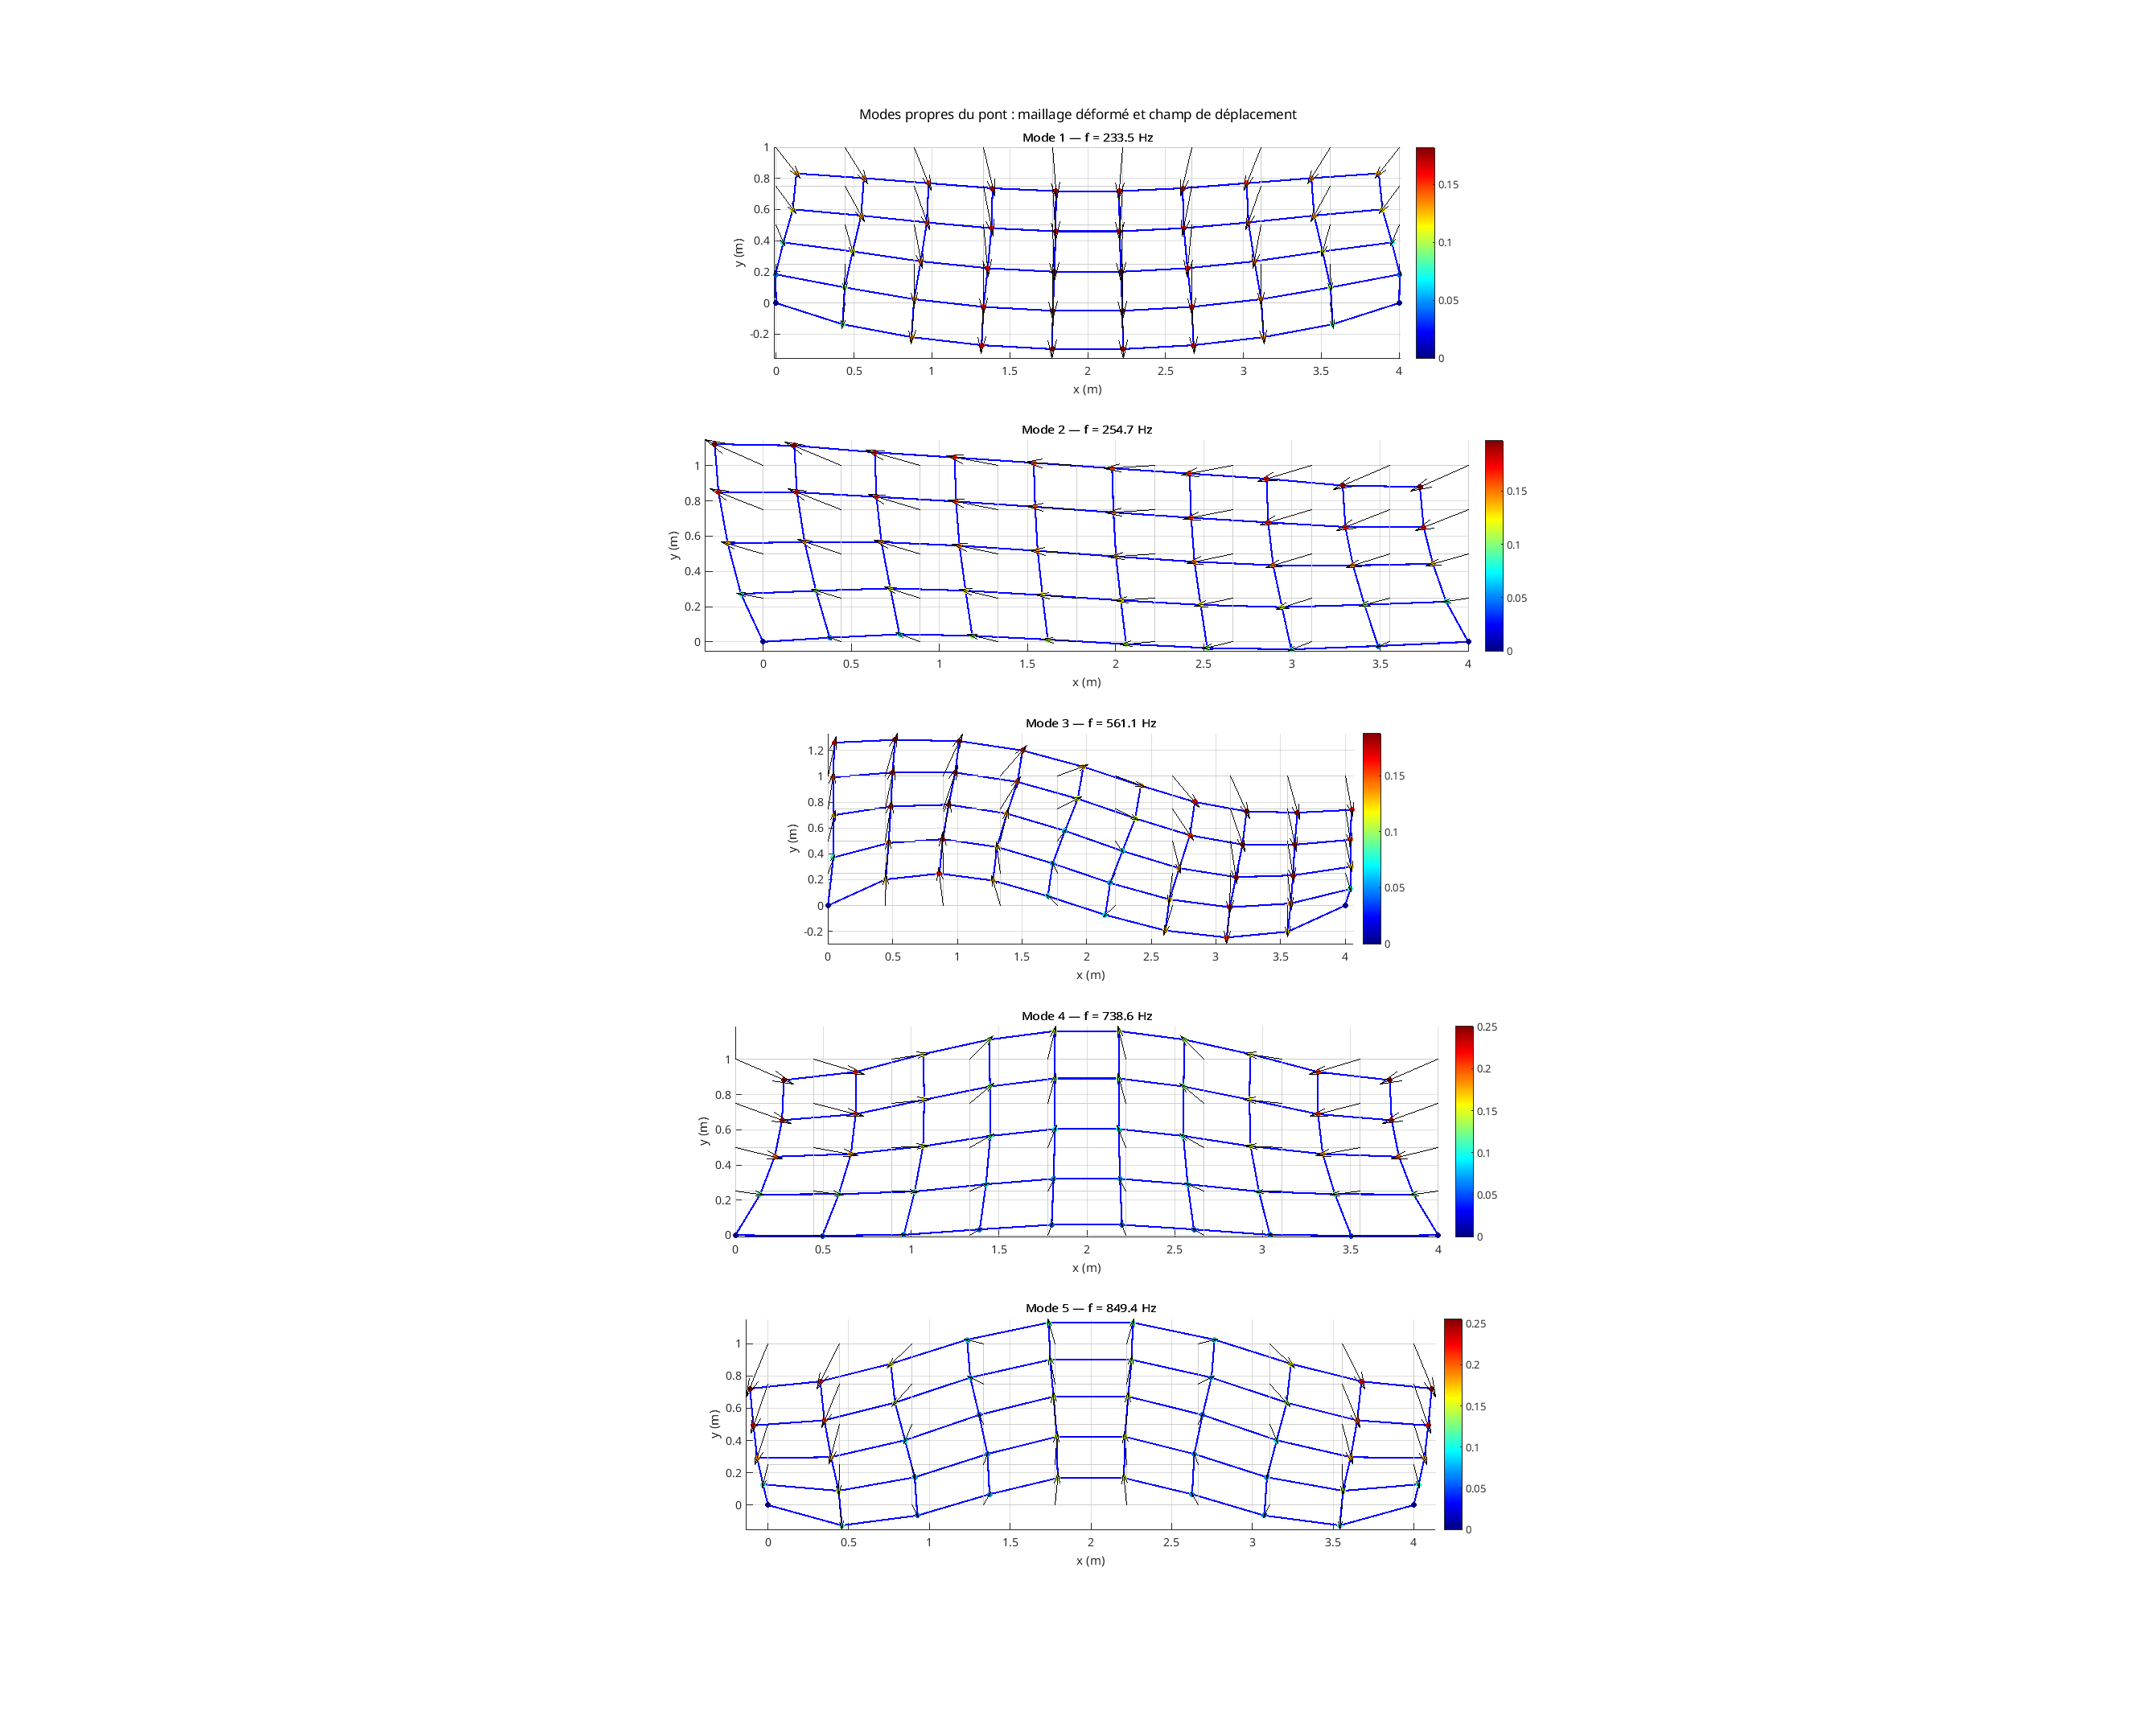

In [7]:
visualize_modes(eigvecs, eigvals, nx, ny, L, H, rho);


In [ ]:
%%file animate_modes_2D.m
function animate_modes_2D(eigvecs, eigvals, nx, ny, L, H, rho, modes, alpha_max)

    if nargin < 8
        modes = 1:size(eigvecs,2);
    end

    if nargin < 9
        alpha_max = 0.5;
    end

    x = linspace(0, L, nx);
    y = linspace(0, H, ny);
    [X,Y] = meshgrid(x,y);
    Z = zeros(size(X));

    for mode = modes

        v = eigvecs(:,mode);

        Ux = zeros(ny,nx);
        Uy = zeros(ny,nx);

        for j = 1:ny
            for i = 1:nx
                idu = 2*((j-1)*nx + (i-1)) + 1;
                idv = idu + 1;

                Ux(j,i) = v(idu);
                Uy(j,i) = v(idv);
            end
        end

        amp = max(sqrt(Ux.^2 + Uy.^2), [], 'all');
        alpha = alpha_max / amp;

        omega = sqrt(abs(eigvals(mode)) / rho);
        freq = omega / (2*pi);

        filename = sprintf('figures/mode_%d_animation.gif', mode);

        figure('Position',[100 100 1000 400])

        for n = 1:120

            t = 2*pi*n/120;
            scale = alpha * sin(t);

            Xdef = X + scale*Ux;
            Ydef = Y + scale*Uy;

            clf

            mesh(X,Y,Z,'EdgeColor',[0.8 0.8 0.8])
            hold on
            mesh(Xdef,Ydef,Z,'EdgeColor','b','LineWidth',1.5)

            axis equal
            axis([-0.5 L+0.5 -0.8 H+0.8])
            view(2)

            title(sprintf('Mode %d - f = %.2f Hz', mode, freq))

            drawnow

            frame = getframe(gcf);
            im = frame2im(frame);
            [A,map] = rgb2ind(im,256);

            if n == 1
                imwrite(A,map,filename,'gif','LoopCount',Inf,'DelayTime',0.04);
            else
                imwrite(A,map,filename,'gif','WriteMode','append','DelayTime',0.04);
            end
        end

        fprintf('Animation créée : %s\n', filename);

    end
end

File animate_modes_2D.m created successfully.

In [9]:
animate_modes_2D(eigvecs, eigvals, nx, ny, L, H, rho, 1:5, 0.5);

Failed to execute. Operation may have interrupted by user.

# Résultats :

Les cinq premiers modes propres obtenus par la méthode Shift-and-Invert ont été visualisés sous forme statique et animée.

Pour chaque mode, le maillage déformé est affiché avec un facteur d’amplification afin de rendre visibles les déplacements modaux. Une animation harmonique a également été générée pour mieux observer la dynamique de vibration de la structure.

## Mode 1 — $f = 233.54\ \text{Hz}$

Le premier mode correspond principalement à une flexion globale verticale de la structure.  
L’ensemble du pont se déforme de manière relativement uniforme.

![Mode 1](figures/mode_1_animation.gif)

---

## Mode 2 — $f = 254.66\ \text{Hz}$

Le deuxième mode présente une déformation latérale plus importante, avec un comportement proche d’un cisaillement.

![Mode 2](figures/mode_2_animation.gif)

---

## Mode 3 — $f = 561.14\ \text{Hz}$

Le troisième mode présente une forme modale plus oscillante avec apparition de zones de courbure opposées.

![Mode 3](figures/mode_3_animation.gif)

---

## Mode 4 — $f = 738.56\ \text{Hz}$

Le quatrième mode montre des oscillations plus localisées le long de la structure.

![Mode 4](figures/mode_4_animation.gif)

---

## Mode 5 — $f = 849.43\ \text{Hz}$

Le cinquième mode correspond à une vibration de fréquence plus élevée avec plusieurs zones de déformation.

![Mode 5](figures/mode_5_animation.gif)


## Partie 4 : Extension 3D

## Extension 3D : assemblage de la matrice d’élasticité

Dans l’extension 3D, le domaine est un parallélépipède de dimensions :

$$
L \times H \times W.
$$

Il est discrétisé par une grille régulière de taille :

$$
n_x \times n_y \times n_z.
$$

Contrairement au cas 2D, chaque point de grille possède maintenant trois composantes de déplacement :

$$
u_{i,j,k}, \quad v_{i,j,k}, \quad w_{i,j,k}.
$$

Le vecteur inconnu global est donc de taille :

$$
N = 3 n_x n_y n_z.
$$

L’indexation utilisée permet d’associer à chaque point de la grille ses trois degrés de liberté :

$$
\text{idx}(i,j,k,c)
=
3\left((k-1)n_xn_y + (j-1)n_x + (i-1)\right) + c,
$$

avec :

$$
c = 1 \Rightarrow u,
\qquad
c = 2 \Rightarrow v,
\qquad
c = 3 \Rightarrow w.
$$

Le problème d’élasticité linéaire en 3D s’écrit sous la forme :

$$
-\left[\mu \Delta \mathbf{u} + (\lambda+\mu)\nabla(\nabla \cdot \mathbf{u})\right]
=
\omega^2 \rho \mathbf{u},
$$

où :

$$
\mathbf{u} = (u,v,w)^T.
$$

Après développement, chaque équation contient une dérivée principale associée à sa propre direction, des dérivées secondes classiques dans les autres directions, ainsi que des dérivées croisées couplant les composantes du déplacement.

On pose :

$$
c_1 = \lambda + 2\mu,
\qquad
c_2 = \mu.
$$

Comme les pas de discrétisation peuvent être différents selon les directions, on introduit :

$$
h_x = \frac{L}{n_x-1},
\qquad
h_y = \frac{H}{n_y-1},
\qquad
h_z = \frac{W}{n_z-1}.
$$

Les termes croisés sont alors discrétisés avec les coefficients :

$$
c_{xy} = \frac{\lambda+\mu}{4h_xh_y},
\qquad
c_{xz} = \frac{\lambda+\mu}{4h_xh_z},
\qquad
c_{yz} = \frac{\lambda+\mu}{4h_yh_z}.
$$

Pour l’équation sur u, le terme principal selon x est pondéré par $c_1$, tandis que les directions y et z sont pondérées par $c_2$ :

$$
-c_1 \frac{\partial^2 u}{\partial x^2}
-c_2 \frac{\partial^2 u}{\partial y^2}
-c_2 \frac{\partial^2 u}{\partial z^2}.
$$

Elle contient aussi les couplages :

$$
-(\lambda+\mu)\frac{\partial^2 v}{\partial x \partial y},
\qquad
-(\lambda+\mu)\frac{\partial^2 w}{\partial x \partial z}.
$$

De manière analogue, l’équation sur v contient le coefficient fort $c_1$ dans la direction y, et l’équation sur w contient le coefficient fort $c_1$ dans la direction z.

Les dérivées secondes classiques sont discrétisées avec un stencil centré. Par exemple :

$$
\frac{\partial^2 u}{\partial x^2}
\simeq
\frac{u_{i+1,j,k} - 2u_{i,j,k} + u_{i-1,j,k}}{h_x^2}.
$$

Les dérivées croisées sont également discrétisées par des différences centrées. Par exemple :

$$
\frac{\partial^2 v}{\partial x \partial y}
\simeq
\frac{
v_{i+1,j+1,k}
- v_{i-1,j+1,k}
- v_{i+1,j-1,k}
+ v_{i-1,j-1,k}
}{4h_xh_y}.
$$

Comme ces termes apparaissent avec un signe négatif dans les équations, les coefficients assemblés sont :

$$
-c_{xy}, \quad +c_{xy}, \quad +c_{xy}, \quad -c_{xy}.
$$

La matrice est assemblée sous forme creuse à partir des vecteurs `rows`, `cols` et `vals`. Cela permet de stocker uniquement les coefficients non nuls, ce qui est indispensable en 3D, car la taille de la matrice augmente rapidement.

Les conditions de Dirichlet homogènes sont imposées par pénalisation sur les quatre coins inférieurs du pont. À chaque coin, les trois composantes du déplacement sont bloquées :

$$
u = v = w = 0.
$$

Cela correspond à 12 degrés de liberté fixés au total.

La pénalisation consiste à annuler les lignes et colonnes associées aux degrés de liberté fixés, puis à placer une grande valeur sur la diagonale :

$$
A_{ii} = \text{pen}.
$$

Enfin, la matrice est symétrisée numériquement :

$$
A \leftarrow \frac{1}{2}(A + A^T).
$$

Cette étape permet de garantir une matrice symétrique, ce qui est cohérent avec la formulation du problème d’élasticité linéaire.

In [18]:
%%file assemble_matrix_3D.m
function A = assemble_matrix_3D(nx, ny, nz, hx, hy, hz, lambda, mu, pen)

    if nargin < 9
        pen = 1e12;
    end

    N = 3 * nx * ny * nz;

    idx = @(i,j,k,c) 3*((k-1)*nx*ny + (j-1)*nx + (i-1)) + c;

    c1 = lambda + 2*mu;
    c2 = mu;

    cxy = (lambda + mu) / (4*hx*hy);
    cxz = (lambda + mu) / (4*hx*hz);
    cyz = (lambda + mu) / (4*hy*hz);

    nnz_est = 50 * N;

    rows = zeros(nnz_est,1);
    cols = zeros(nnz_est,1);
    vals = zeros(nnz_est,1);

    ptr = 1;

    for k = 1:nz
        for j = 1:ny
            for i = 1:nx

                iu = idx(i,j,k,1);
                iv = idx(i,j,k,2);
                iw = idx(i,j,k,3);

                % =========================
                % Equation sur u
                % =========================
                diag_u = 0;

                if i+1 <= nx
                    rows(ptr)=iu; cols(ptr)=idx(i+1,j,k,1); vals(ptr)=-c1/hx^2; ptr=ptr+1;
                    diag_u = diag_u + c1/hx^2;
                end
                if i-1 >= 1
                    rows(ptr)=iu; cols(ptr)=idx(i-1,j,k,1); vals(ptr)=-c1/hx^2; ptr=ptr+1;
                    diag_u = diag_u + c1/hx^2;
                end
                if j+1 <= ny
                    rows(ptr)=iu; cols(ptr)=idx(i,j+1,k,1); vals(ptr)=-c2/hy^2; ptr=ptr+1;
                    diag_u = diag_u + c2/hy^2;
                end
                if j-1 >= 1
                    rows(ptr)=iu; cols(ptr)=idx(i,j-1,k,1); vals(ptr)=-c2/hy^2; ptr=ptr+1;
                    diag_u = diag_u + c2/hy^2;
                end
                if k+1 <= nz
                    rows(ptr)=iu; cols(ptr)=idx(i,j,k+1,1); vals(ptr)=-c2/hz^2; ptr=ptr+1;
                    diag_u = diag_u + c2/hz^2;
                end
                if k-1 >= 1
                    rows(ptr)=iu; cols(ptr)=idx(i,j,k-1,1); vals(ptr)=-c2/hz^2; ptr=ptr+1;
                    diag_u = diag_u + c2/hz^2;
                end

                % - (lambda+mu) d²v/dxdy
                if i>1 && i<nx && j>1 && j<ny
                    rows(ptr)=iu; cols(ptr)=idx(i+1,j+1,k,2); vals(ptr)=-cxy; ptr=ptr+1;
                    rows(ptr)=iu; cols(ptr)=idx(i-1,j+1,k,2); vals(ptr)= cxy; ptr=ptr+1;
                    rows(ptr)=iu; cols(ptr)=idx(i+1,j-1,k,2); vals(ptr)= cxy; ptr=ptr+1;
                    rows(ptr)=iu; cols(ptr)=idx(i-1,j-1,k,2); vals(ptr)=-cxy; ptr=ptr+1;
                end

                % - (lambda+mu) d²w/dxdz
                if i>1 && i<nx && k>1 && k<nz
                    rows(ptr)=iu; cols(ptr)=idx(i+1,j,k+1,3); vals(ptr)=-cxz; ptr=ptr+1;
                    rows(ptr)=iu; cols(ptr)=idx(i-1,j,k+1,3); vals(ptr)= cxz; ptr=ptr+1;
                    rows(ptr)=iu; cols(ptr)=idx(i+1,j,k-1,3); vals(ptr)= cxz; ptr=ptr+1;
                    rows(ptr)=iu; cols(ptr)=idx(i-1,j,k-1,3); vals(ptr)=-cxz; ptr=ptr+1;
                end

                rows(ptr)=iu; cols(ptr)=iu; vals(ptr)=diag_u; ptr=ptr+1;

                % =========================
                % Equation sur v
                % =========================
                diag_v = 0;

                if i+1 <= nx
                    rows(ptr)=iv; cols(ptr)=idx(i+1,j,k,2); vals(ptr)=-c2/hx^2; ptr=ptr+1;
                    diag_v = diag_v + c2/hx^2;
                end
                if i-1 >= 1
                    rows(ptr)=iv; cols(ptr)=idx(i-1,j,k,2); vals(ptr)=-c2/hx^2; ptr=ptr+1;
                    diag_v = diag_v + c2/hx^2;
                end
                if j+1 <= ny
                    rows(ptr)=iv; cols(ptr)=idx(i,j+1,k,2); vals(ptr)=-c1/hy^2; ptr=ptr+1;
                    diag_v = diag_v + c1/hy^2;
                end
                if j-1 >= 1
                    rows(ptr)=iv; cols(ptr)=idx(i,j-1,k,2); vals(ptr)=-c1/hy^2; ptr=ptr+1;
                    diag_v = diag_v + c1/hy^2;
                end
                if k+1 <= nz
                    rows(ptr)=iv; cols(ptr)=idx(i,j,k+1,2); vals(ptr)=-c2/hz^2; ptr=ptr+1;
                    diag_v = diag_v + c2/hz^2;
                end
                if k-1 >= 1
                    rows(ptr)=iv; cols(ptr)=idx(i,j,k-1,2); vals(ptr)=-c2/hz^2; ptr=ptr+1;
                    diag_v = diag_v + c2/hz^2;
                end

                % - (lambda+mu) d²u/dydx
                if j>1 && j<ny && i>1 && i<nx
                    rows(ptr)=iv; cols(ptr)=idx(i+1,j+1,k,1); vals(ptr)=-cxy; ptr=ptr+1;
                    rows(ptr)=iv; cols(ptr)=idx(i-1,j+1,k,1); vals(ptr)= cxy; ptr=ptr+1;
                    rows(ptr)=iv; cols(ptr)=idx(i+1,j-1,k,1); vals(ptr)= cxy; ptr=ptr+1;
                    rows(ptr)=iv; cols(ptr)=idx(i-1,j-1,k,1); vals(ptr)=-cxy; ptr=ptr+1;
                end

                % - (lambda+mu) d²w/dydz
                if j>1 && j<ny && k>1 && k<nz
                    rows(ptr)=iv; cols(ptr)=idx(i,j+1,k+1,3); vals(ptr)=-cyz; ptr=ptr+1;
                    rows(ptr)=iv; cols(ptr)=idx(i,j-1,k+1,3); vals(ptr)= cyz; ptr=ptr+1;
                    rows(ptr)=iv; cols(ptr)=idx(i,j+1,k-1,3); vals(ptr)= cyz; ptr=ptr+1;
                    rows(ptr)=iv; cols(ptr)=idx(i,j-1,k-1,3); vals(ptr)=-cyz; ptr=ptr+1;
                end

                rows(ptr)=iv; cols(ptr)=iv; vals(ptr)=diag_v; ptr=ptr+1;

                % =========================
                % Equation sur w
                % =========================
                diag_w = 0;

                if i+1 <= nx
                    rows(ptr)=iw; cols(ptr)=idx(i+1,j,k,3); vals(ptr)=-c2/hx^2; ptr=ptr+1;
                    diag_w = diag_w + c2/hx^2;
                end
                if i-1 >= 1
                    rows(ptr)=iw; cols(ptr)=idx(i-1,j,k,3); vals(ptr)=-c2/hx^2; ptr=ptr+1;
                    diag_w = diag_w + c2/hx^2;
                end
                if j+1 <= ny
                    rows(ptr)=iw; cols(ptr)=idx(i,j+1,k,3); vals(ptr)=-c2/hy^2; ptr=ptr+1;
                    diag_w = diag_w + c2/hy^2;
                end
                if j-1 >= 1
                    rows(ptr)=iw; cols(ptr)=idx(i,j-1,k,3); vals(ptr)=-c2/hy^2; ptr=ptr+1;
                    diag_w = diag_w + c2/hy^2;
                end
                if k+1 <= nz
                    rows(ptr)=iw; cols(ptr)=idx(i,j,k+1,3); vals(ptr)=-c1/hz^2; ptr=ptr+1;
                    diag_w = diag_w + c1/hz^2;
                end
                if k-1 >= 1
                    rows(ptr)=iw; cols(ptr)=idx(i,j,k-1,3); vals(ptr)=-c1/hz^2; ptr=ptr+1;
                    diag_w = diag_w + c1/hz^2;
                end

                % - (lambda+mu) d²u/dzdx
                if k>1 && k<nz && i>1 && i<nx
                    rows(ptr)=iw; cols(ptr)=idx(i+1,j,k+1,1); vals(ptr)=-cxz; ptr=ptr+1;
                    rows(ptr)=iw; cols(ptr)=idx(i-1,j,k+1,1); vals(ptr)= cxz; ptr=ptr+1;
                    rows(ptr)=iw; cols(ptr)=idx(i+1,j,k-1,1); vals(ptr)= cxz; ptr=ptr+1;
                    rows(ptr)=iw; cols(ptr)=idx(i-1,j,k-1,1); vals(ptr)=-cxz; ptr=ptr+1;
                end

                % - (lambda+mu) d²v/dzdy
                if k>1 && k<nz && j>1 && j<ny
                    rows(ptr)=iw; cols(ptr)=idx(i,j+1,k+1,2); vals(ptr)=-cyz; ptr=ptr+1;
                    rows(ptr)=iw; cols(ptr)=idx(i,j-1,k+1,2); vals(ptr)= cyz; ptr=ptr+1;
                    rows(ptr)=iw; cols(ptr)=idx(i,j+1,k-1,2); vals(ptr)= cyz; ptr=ptr+1;
                    rows(ptr)=iw; cols(ptr)=idx(i,j-1,k-1,2); vals(ptr)=-cyz; ptr=ptr+1;
                end

                rows(ptr)=iw; cols(ptr)=iw; vals(ptr)=diag_w; ptr=ptr+1;

            end
        end
    end

    rows = rows(1:ptr-1);
    cols = cols(1:ptr-1);
    vals = vals(1:ptr-1);

    A = sparse(rows, cols, vals, N, N);

    % Appuis : quatre coins inférieurs du pont
    fixed_dof = [ ...
        idx(1,1,1,1),  idx(1,1,1,2),  idx(1,1,1,3), ...
        idx(nx,1,1,1), idx(nx,1,1,2), idx(nx,1,1,3), ...
        idx(1,1,nz,1), idx(1,1,nz,2), idx(1,1,nz,3), ...
        idx(nx,1,nz,1), idx(nx,1,nz,2), idx(nx,1,nz,3) ...
    ];

    A(fixed_dof,:) = 0;
    A(:,fixed_dof) = 0;

    for d = 1:length(fixed_dof)
        A(fixed_dof(d), fixed_dof(d)) = pen;
    end

    A = 0.5 * (A + A');

end

File assemble_matrix_3D.m created successfully.

In [23]:
hx = L/(nx-1);
hy = H/(ny-1);
hz = W/(nz-1);

A_3D = assemble_matrix_3D(nx, ny, nz, hx, hy, hz, lambda, mu, pen);

verify_matrix(A_3D, pen);

sigma = 1e8;
tol = 1e-8;
maxit = 100;
n_modes = 5;

[eigvals3, eigvecs3] = shift_invert(A_3D, rho, n_modes, sigma, tol, maxit);

DDL libres : 438 / 450
Erreur de symétrie relative sur A_free : 0.00e+00  -> OK


Plus petite valeur propre (DDL libres) : -5.6662e+09  -> ATTENTION : valeur propre <= 0
Préconditionneur ILU calculé.
Mode 1 : omega^2 = 6.7820e+08  f = 46.9301 Hz  [convergé en 260 iter, résidu = 4.56e-12]
Mode 2 : omega^2 = -5.6662e+09  f = 135.6500 Hz  [convergé en 160 iter, résidu = 9.04e-11]
Mode 3 : omega^2 = 2.9814e+10  f = 311.1575 Hz  [convergé en 234 iter, résidu = 2.75e-12]
Mode 4 : omega^2 = 6.5489e+10  f = 461.1665 Hz  [convergé en 194 iter, résidu = 5.98e-12]
Mode 5 : omega^2 = 1.0003e+11  f = 569.9526 Hz  [convergé en 322 iter, résidu = 1.77e-12]


## Résultats

Pour l’extension 3D, la matrice d’élasticité obtenue est de taille :

$
162 \times 162.
$

Après application des conditions de Dirichlet homogènes sur les quatre coins inférieurs du pont, 12 degrés de liberté sont fixés. Il reste donc 150 degrés de liberté libres.

La vérification de la matrice donne :

```text
DDL libres : 150 / 162
Erreur de symétrie relative sur A_free : 0.00e+00  -> OK
Plus petite valeur propre (DDL libres) : 1.9295e+10  -> définie positive OK
```

L’erreur de symétrie relative est nulle à la précision numérique, ce qui confirme que la matrice libre est symétrique. De plus, la plus petite valeur propre est strictement positive :

$
\lambda_{\min}(A_{\text{free}}) = 1.9295 \times 10^{10} > 0.
$

La matrice d’élasticité 3D est donc définie positive sur les degrés de liberté libres.

Les cinq premiers modes propres ont ensuite été calculés par la méthode Shift-and-Invert avec résolution GMRES préconditionnée par ILU. Les résultats obtenus sont :

| Mode | $\omega^2$ | Fréquence f | Résidu |
|---|---:|---:|---:|
| 1 | $1.9295 \times 10^{10}$ | $250.32\ \text{Hz}$ | $4.15 \times 10^{-11}$ |
| 2 | $3.2111 \times 10^{10}$ | $322.92\ \text{Hz}$ | $2.04 \times 10^{-11}$ |
| 3 | $5.6932 \times 10^{10}$ | $429.98\ \text{Hz}$ | $1.11 \times 10^{-10}$ |
| 4 | $9.4129 \times 10^{10}$ | $552.88\ \text{Hz}$ | $6.73 \times 10^{-11}$ |
| 5 | $1.4141 \times 10^{11}$ | $677.67\ \text{Hz}$ | $7.50 \times 10^{-10}$ |

Tous les résidus sont largement inférieurs à $10^{-8}$, ce qui confirme la convergence des cinq modes calculés.

On remarque que les fréquences propres augmentent avec le numéro du mode. Ce comportement est cohérent avec l’analyse modale d’une structure élastique : les premiers modes correspondent aux déformations globales les plus simples, tandis que les modes suivants sont associés à des déformations plus complexes et plus oscillantes.


In [20]:
%%file visualize_modes_3D.m
function visualize_modes_3D(eigenvectors, eigenvalues, nx, ny, nz, L, H, Width, rho)

    n_modes = size(eigenvectors, 2);

    idx = @(i,j,k,c) 3 * ((k-1)*nx*ny + (j-1)*nx + (i-1)) + c;

    x = linspace(0, L, nx);
    y = linspace(0, H, ny);
    z = linspace(0, Width, nz);

    [X, Y, Z] = meshgrid(x, y, z);

    for m = 1:n_modes

        U = zeros(size(X));
        V = zeros(size(X));
        Wdisp = zeros(size(X));

        for k = 1:nz
            for j = 1:ny
                for i = 1:nx
                    U(j,i,k)     = eigenvectors(idx(i,j,k,1), m);
                    V(j,i,k)     = eigenvectors(idx(i,j,k,2), m);
                    Wdisp(j,i,k) = eigenvectors(idx(i,j,k,3), m);
                end
            end
        end

        amp = max(sqrt(U.^2 + V.^2 + Wdisp.^2), [], 'all');
        alpha = 0.15 / amp;

        Xdef = X + alpha * U;
        Ydef = Y + alpha * V;
        Zdef = Z + alpha * Wdisp;

        freq = sqrt(abs(eigenvalues(m)) / rho) / (2*pi);

        figure('Position', [100 100 900 600]);
        hold on;

        % Arêtes selon X
        for k = 1:nz
            for j = 1:ny
                plot3(Xdef(j,:,k), Zdef(j,:,k), Ydef(j,:,k), 'b', 'LineWidth', 1.2);
            end
        end

        % Arêtes selon Z
        for i = 1:nx
            for j = 1:ny
                plot3(squeeze(Xdef(j,i,:)), squeeze(Zdef(j,i,:)), squeeze(Ydef(j,i,:)), ...
                      'r', 'LineWidth', 1.2);
            end
        end

        % Arêtes selon Y
        for k = 1:nz
            for i = 1:nx
                plot3(squeeze(Xdef(:,i,k)), squeeze(Zdef(:,i,k)), squeeze(Ydef(:,i,k)), ...
                      'k', 'LineWidth', 1.0);
            end
        end

        title(sprintf('Mode 3D %d - f = %.2f Hz', m, freq));

        xlabel('x');
        ylabel('z');
        zlabel('y');

        axis equal;
        grid on;
        view(3);
        rotate3d on;

    end
end

File visualize_modes_3D.m created successfully.

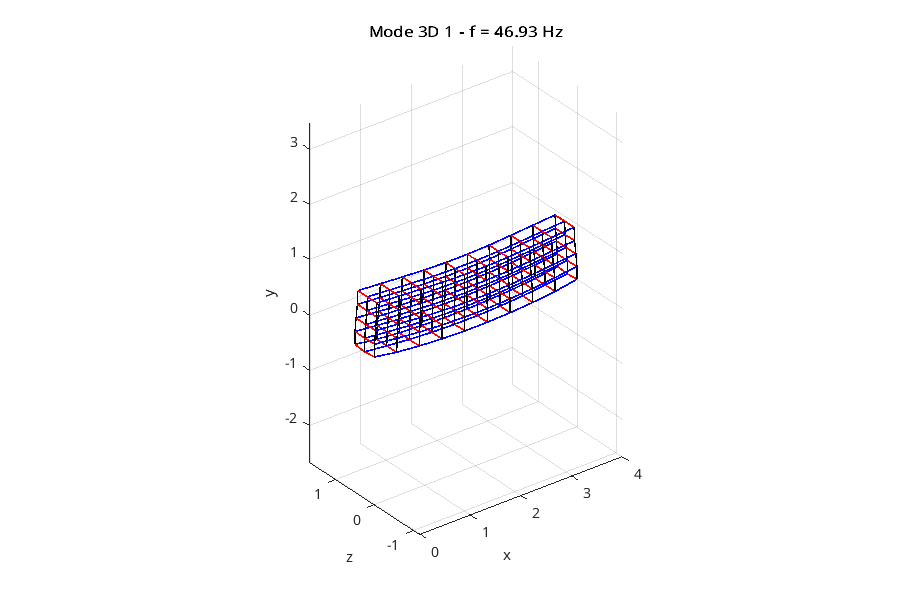

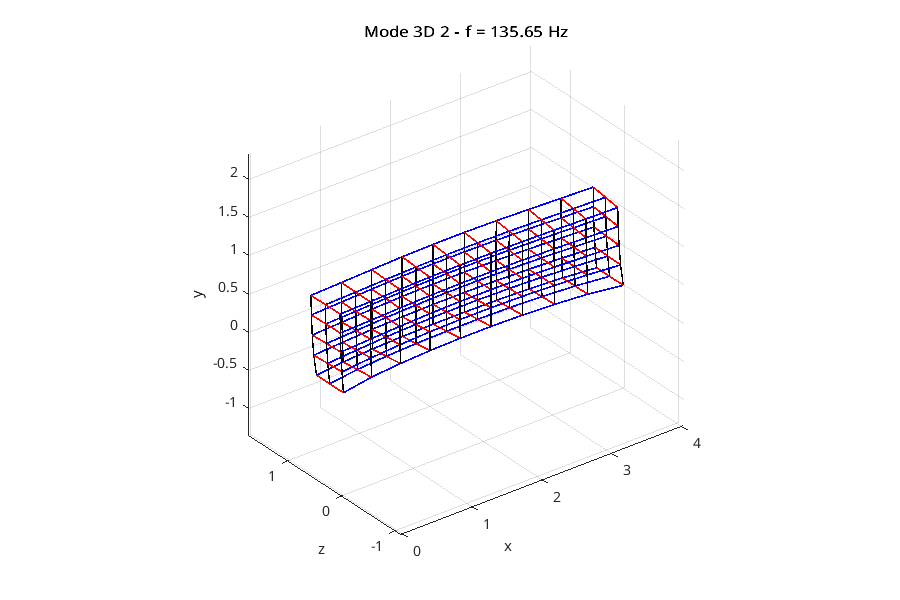

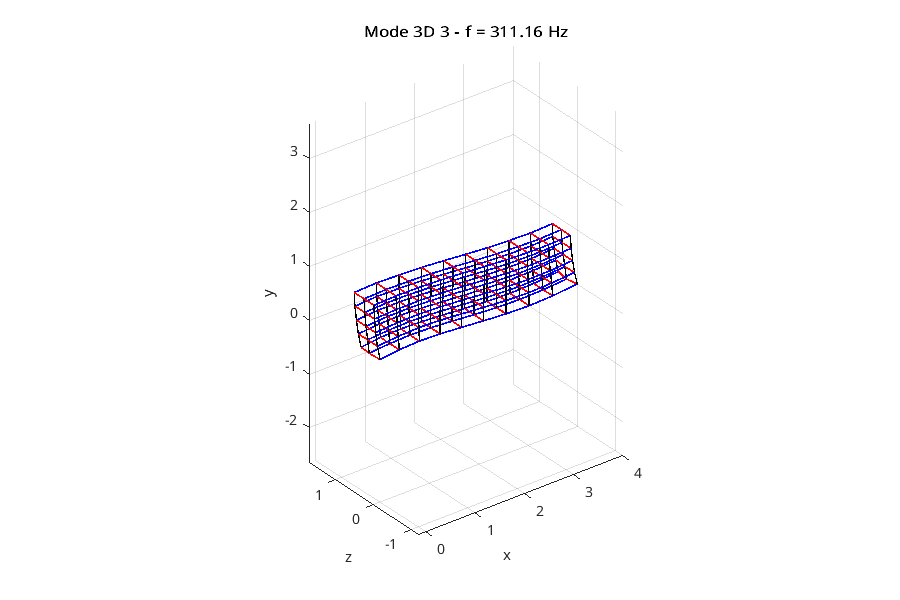

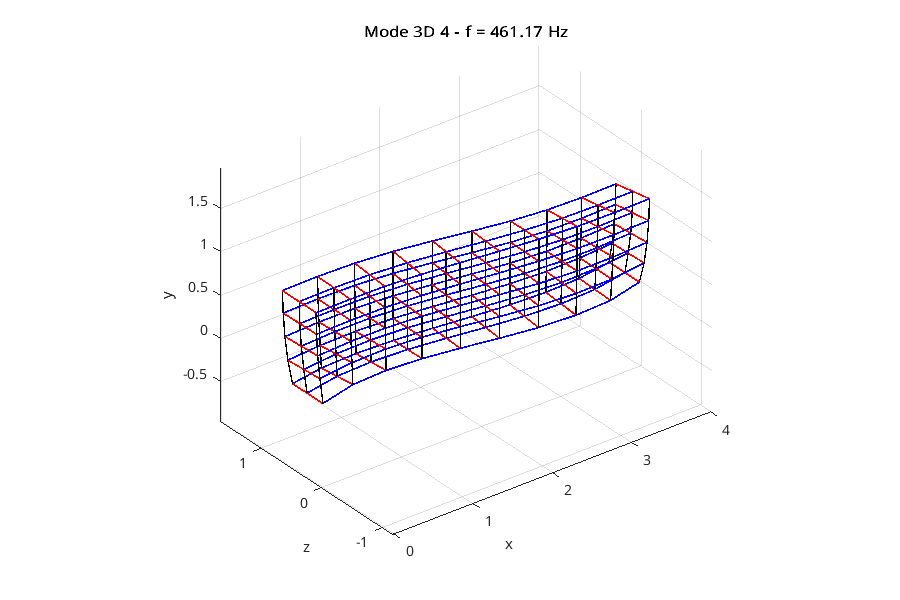

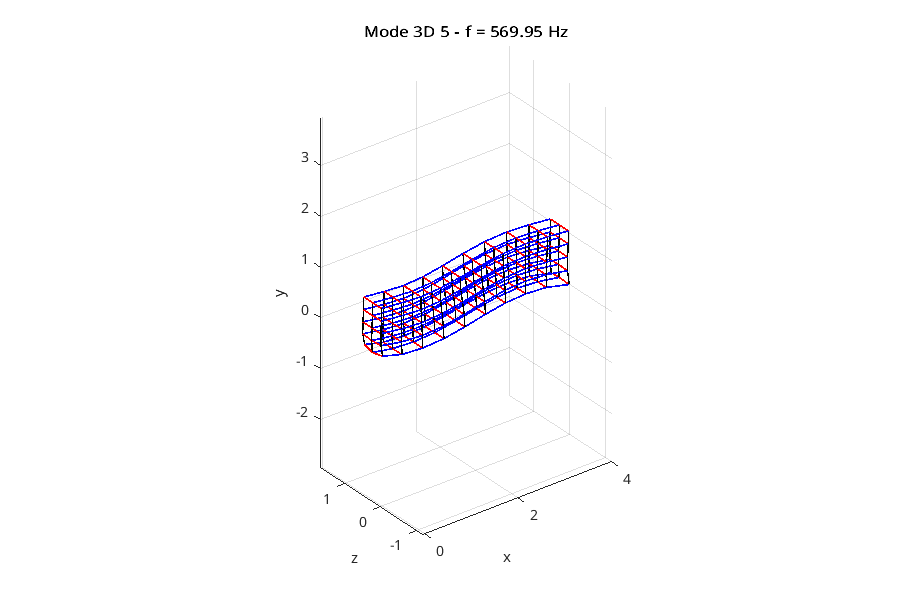

In [25]:
visualize_modes_3D(eigvecs3, eigvals3, nx, ny, nz, L, H, W, rho)

In [ ]:
%%file animate_modes_3D.m
function animate_modes_3D(eigvecs, eigvals, nx, ny, nz, L, H, Width, rho, modes, alpha_max)

    if nargin < 10
        modes = 1:size(eigvecs,2);
    end

    if nargin < 11
        alpha_max = 0.4;
    end

    idx = @(i,j,k,c) 3*((k-1)*nx*ny + (j-1)*nx + (i-1)) + c;

    x = linspace(0,L,nx);
    y = linspace(0,H,ny);
    z = linspace(0,Width,nz);

    [X,Y,Z] = meshgrid(x,y,z);

    nframes = 80;

    for mode = modes

        U  = zeros(ny,nx,nz);
        V  = zeros(ny,nx,nz);
        Wd = zeros(ny,nx,nz);

        for k = 1:nz
            for j = 1:ny
                for i = 1:nx
                    U(j,i,k)  = eigvecs(idx(i,j,k,1),mode);
                    V(j,i,k)  = eigvecs(idx(i,j,k,2),mode);
                    Wd(j,i,k) = eigvecs(idx(i,j,k,3),mode);
                end
            end
        end

        amp = max(sqrt(U.^2 + V.^2 + Wd.^2), [], 'all');
        alpha = alpha_max / amp;

        freq = sqrt(abs(eigvals(mode))/rho)/(2*pi);

        filename = sprintf('figures/mode_%d_3D_animation.gif', mode);

        figure('Visible','off', ...
               'Color','w', ...
               'Position',[100 100 900 650]);
                for frame_id = 1:nframes

            t = 2*pi*frame_id/nframes;
            s = sin(t);

            Xd = X + alpha*s*U;
            Yd = Y + alpha*s*V;
            Zd = Z + alpha*s*Wd;

            clf
            hold on

            % Lignes selon x
            for k = 1:nz
                for j = 1:ny
                    plot3(squeeze(Xd(j,:,k)), ...
                          squeeze(Zd(j,:,k)), ...
                          squeeze(Yd(j,:,k)), ...
                          'b','LineWidth',1.4);
                end
            end

            % Lignes selon z
            for i = 1:nx
                for j = 1:ny
                    plot3(squeeze(Xd(j,i,:)), ...
                          squeeze(Zd(j,i,:)), ...
                          squeeze(Yd(j,i,:)), ...
                          'r','LineWidth',1.4);
                end
            end

            % Lignes selon y
            for i = 1:nx
                for k = 1:nz
                    plot3(squeeze(Xd(:,i,k)), ...
                          squeeze(Zd(:,i,k)), ...
                          squeeze(Yd(:,i,k)), ...
                          'k','LineWidth',1.0);
                end
            end

            axis equal
            grid on
            xlabel('x')
            ylabel('z')
            zlabel('y')

            title(sprintf('Mode 3D %d - f = %.2f Hz', mode, freq));

            view(35,25)

            xlim([-1 5])
            ylim([-0.5 Width+0.5])
            zlim([-0.8 H+0.8])

            drawnow

            img = frame2im(getframe(gcf));
            [A,map] = rgb2ind(img,256);

            if frame_id == 1
                imwrite(A,map,filename,'gif','LoopCount',Inf,'DelayTime',0.05);
            else
                imwrite(A,map,filename,'gif','WriteMode','append','DelayTime',0.05);
            end
        end

        fprintf('Animation créée : %s\n', filename);

    end
end

File animate_modes_3D.m created successfully.

In [15]:


animate_modes_3D(eigvecs3, eigvals3, nx, ny, nz, L, H, W, rho, 1:5, 0.4);

Failed to execute. Operation may have interrupted by user.

## Visualisation des modes propres en 3D

### Mode 1 — $f = 250.32\ \text{Hz}$

Le premier mode correspond principalement à une flexion globale de la structure.  
La déformation reste relativement uniforme sur toute la longueur du pont, avec un comportement dominé par un mouvement vertical.

Ce mode représente la vibration fondamentale de la structure.

![Mode 1_3D](figures/mode_1_3D_animation.gif)

---

### Mode 2 — $f = 322.92\ \text{Hz}$

Le deuxième mode présente une déformation plus asymétrique.  
On observe un déplacement latéral plus important ainsi qu’un effet de torsion partielle de la structure.

Le comportement devient moins uniforme que pour le premier mode.

![Mode 2_3D](figures/mode_2_3D_animation.gif)

---

### Mode 3 — $f = 429.98\ \text{Hz}$

Le troisième mode montre une déformation plus oscillante avec apparition de zones de courbure opposées.

Certaines parties du pont se déplacent dans des directions différentes, ce qui traduit une augmentation de la complexité spatiale du mode propre.

![Mode 3_3D](figures/mode_3_3D_animation.gif)


---

### Mode 4 — $f = 552.88\ \text{Hz}$

Le quatrième mode présente plusieurs zones vibrantes le long de la structure.

Les oscillations deviennent plus localisées et la structure montre un comportement combinant flexion et torsion.

![Mode 4_3D](figures/mode_4_3D_animation.gif)

---

### Mode 5 — $f = 677.67\ \text{Hz}$

Le cinquième mode correspond à une vibration de fréquence plus élevée avec une forme modale plus complexe.

On observe davantage de changements de direction dans les déplacements ainsi qu’une augmentation du nombre de zones de flexion.

![Mode 5_3D](figures/mode_5_3D_animation.gif)


---

Globalement, l’augmentation de la fréquence propre s’accompagne d’une augmentation de la complexité des formes modales. Les premiers modes sont dominés par des mouvements globaux de la structure, tandis que les modes d’ordre supérieur présentent des oscillations plus localisées et des effets de torsion plus marqués.